# Testing the DDS overlay (tutorial, part 3)

This notebook belongs to `tutorial/TUTORIAL_DDS.md`. In that tutorial you added a Xilinx DDS to the P501 block design: it generates the TX1
samples inside the FPGA, so no DAC DMA and no buffer are needed any more. Python only writes a few registers (frequency, amplitude, enable).

| test | what it shows |
|---|---|
| 0 | the overlay loads and the register block answers at `0x9C450000` |
| 1 | over the air: a 1 MHz tone from the DDS comes back through TX1 -> RX1 |
| 2 | frequency accuracy for positive and negative frequencies (AD9361 digital loopback) |
| 3 | I/Q order: the mirror image of the tone is far below the tone |
| 4 | amplitude control: halving the register halves the level (-6 dB steps) |
| 5 | enable off silences the DAC, and updates are taken over quickly |

Tests 2-5 use the AD9361's digital loopback (TX data goes to the RX data port inside the chip), so they test the FPGA side exactly,
whatever the antennas do. Test 1 needs TX1 and RX1 antennas near each other, or a cable with at least 40 dB attenuation:
never connect them directly.

## Configuration

In [1]:
BIT       = "/home/xilinx/jupyter_notebooks/p501_dds/p501_dds.bit"   # overlay you built (the .hwh must sit next to it)
FS        = 3_840_000          # sample rate (3.84 MSPS preset of the AD9361 driver)
LO        = 700_000_000        # RF centre frequency, Hz
RF_BW     = 4_000_000          # analog bandwidth, Hz
TX_ATTEN  = 10                 # dB
RX_GAIN   = 45                 # gain-table index 0..76
SETTLE_DB = 45                 # image rejection the AD9361 bring-up waits for (see P501_AD9361_Test.ipynb)
N_CAP     = 8192               # samples per ADC capture

## Test 0 - load the overlay and find the register block

`Overlay(BIT)` programs the PL. The register block you added is `ol.dds_regs`; `P501Dds` (in `p501_dds.py`, next to this notebook) wraps its registers:
frequency word, amplitude, enable, and the commit/applied handshake that moves the values to the sample clock domain.

In [2]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt
from pynq import Overlay, allocate

sys.path.insert(0, '/home/xilinx/jupyter_notebooks')
sys.path.insert(0, '/home/xilinx/jupyter_notebooks/p501_dds')
from ad9361_driver import (AD9361, FIR_RX1, FIR_TX1,
                           REG_ENSM_CONFIG_1, TO_ALERT, FORCE_ALERT_STATE)
from axi_dmac import AxiDmac
import ad9361_full_bypass_test as fb
from ad9361_fir_test import make_fir_coef
from p501_dds import P501Dds

results = {}
def check(name, ok, detail):
    results[name] = (bool(ok), detail)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: {detail}")

ol  = Overlay(BIT)                               # loads the bitstream with the DDS
rxd = AxiDmac(ol.axi_ad9361_adc_dma)             # raw ADC capture (unchanged DMA of the base design)
dds = P501Dds(ol.dds_regs, FS)                   # raises if the register block does not answer

addr = ol.ip_dict["dds_regs"]["phys_addr"]
check("DDS registers found", addr == 0x9C450000, f"dds_regs at 0x{addr:08X}, ID 0x{ol.dds_regs.read(0):08X}")

PASS  DDS registers found: dds_regs at 0x9C450000, ID 0xDD500001


## AD9361 bring-up

The same software flow as the base design: clocks, LO, calibrations, FIR. Two differences: nothing is sent through the DAC DMA (`settle` uses the DDS
as its test tone), and `core_enable` still selects the "DMA" input of the DAC core, which is where the DDS is connected.

In [3]:
OBS = 0x3F5                                      # AD9361 observation/loopback register: bit0 = digital loopback

def capture_adc(n=N_CAP):
    rx = allocate(shape=(n * 2,), dtype=np.int16)
    ok = rxd.transfer_to_memory(rx.physical_address, rx.nbytes)
    rx.invalidate()
    a = np.array(rx); rx.freebuffer()
    return ok, a[0::2].astype(float) + 1j * a[1::2].astype(float)

freqs = np.fft.fftshift(np.fft.fftfreq(N_CAP, 1 / FS))
BIN = freqs[1] - freqs[0]

def spectrum_db(x):
    x = x - x.mean()
    return 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(x * np.hanning(len(x))))) + 1e-9)

def peak_of(m):
    """(frequency in Hz with parabolic interpolation, level in dB) of the strongest line."""
    k = int(np.argmax(m)); a, b, c = m[k - 1], m[k], m[k + 1]
    return freqs[k] + 0.5 * (a - c) / (a - 2 * b + c) * BIN, b

def level_at(m, f0, halfwidth=3):
    return m[np.abs(freqs - f0) <= halfwidth * BIN].max()

def settle(ad, min_rej_db=SETTLE_DB, max_tries=40):
    """Re-enable the chip until the image rejection of a test tone is good (known AD9361 analog-state issue)."""
    dds.set(freq_hz=1e6, amp=0.5)
    for tries in range(1, max_tries + 1):
        ok, x = capture_adc()
        m = spectrum_db(x)
        rej = level_at(m, 1e6) - level_at(m, -1e6)
        if rej >= min_rej_db:
            break
        ad.reg_write(REG_ENSM_CONFIG_1, TO_ALERT | FORCE_ALERT_STATE)
        if tries % 8 == 0:
            ad.tx_quad_calib(RF_BW // 2, RF_BW // 2)
        ad.enable_fdd()
        fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
    return rej, tries

try:
    ad.close()
except NameError:
    pass
ad = AD9361()
ad.power_up_clocks()
assert ad.set_bbpll_rate(983_040_000), "BBPLL did not lock"
ad.set_clock_chain()                                          # 3.84 MSPS
ad.synth_cp_calib(False); ad.synth_cp_calib(True)
rx_ok = ad.set_rx_lo_freq(LO); tx_ok = ad.set_tx_lo_freq(LO)
ad.enable_rx1_tx1()
fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_1, fb.PP_CONF_1)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_2, fb.PP_CONF_2)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_3, fb.PP_CONF_3_LVDS_MODE)
ad.reg_write(fb.REG_RX_CLOCK_DATA_DELAY, fb.RX_CLOCK_DATA_DELAY)
ad.reg_write(fb.REG_TX_CLOCK_DATA_DELAY, fb.TX_CLOCK_DATA_DELAY)
ad.reg_write(fb.REG_LVDS_BIAS_CTRL, fb.LVDS_BIAS_CTRL)
cal = ad.analog_init(rf_rx_bw_hz=RF_BW, rf_tx_bw_hz=RF_BW, rx_freq_hz=LO)
ad.set_rx_manual_gain(RX_GAIN)
ad.set_tx_atten_db(TX_ATTEN)
ad.enable_fdd()
coef = make_fir_coef()
ad.load_fir_filter_coef(FIR_RX1, 0, coef)
ad.load_fir_filter_coef(FIR_TX1, 0, coef)
fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
rej, tries = settle(ad)
print(f"product id 0x{ad.product_id():02X}, ENSM 0x{ad.ensm_state():X}, LO locks {rx_ok}/{tx_ok}, settled after {tries} tries ({rej:.1f} dB image rejection)")
check("AD9361 up", ad.product_id_ok() and rx_ok and tx_ok and ad.ensm_state() == 0xA, f"calibrations {cal}")

product id 0x0A, ENSM 0xA, LO locks True/True, settled after 40 tries (40.8 dB image rejection)
PASS  AD9361 up: calibrations {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}


## Test 1 - a tone over the air

One line: `dds.set(freq_hz=1e6, amp=0.5)`. The tone leaves TX1, travels through the air (or the cable) and is received on RX1. The spectrum shows the tone at +1 MHz
(relative to the LO), and a smaller image at -1 MHz, left over from the analog I/Q imbalance of the chip.

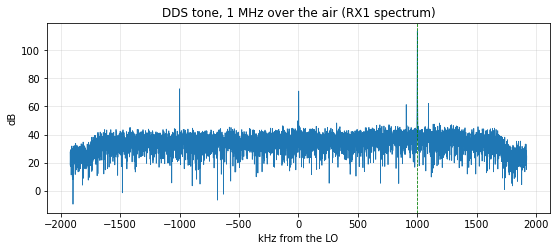

PASS  tone over the air: peak 1000.01 kHz, 78 dB over the floor, image rejection 41.1 dB


In [4]:
dds.set(freq_hz=1e6, amp=0.5)
ok, x = capture_adc()
m = spectrum_db(x)
f_pk, l_pk = peak_of(m)
floor = float(np.median(m))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(freqs / 1e3, m, lw=0.8); ax.axvline(1000, color="g", ls="--", lw=0.8)
ax.set(title="DDS tone, 1 MHz over the air (RX1 spectrum)", xlabel="kHz from the LO", ylabel="dB"); ax.grid(alpha=.3)
plt.show()
check("tone over the air", ok and abs(f_pk - 1e6) < 300 and l_pk - floor > 30,
      f"peak {f_pk/1e3:.2f} kHz, {l_pk - floor:.0f} dB over the floor, image rejection {l_pk - level_at(m, -1e6):.1f} dB")

## Tests 2-5 in digital loopback

The chip now feeds its own TX data back to its RX data port. Nothing analog is involved any more: what we see is what the FPGA sent.

PASS  frequency accuracy: worst error 7 Hz over 8 frequencies from -1.5 to +1.5 MHz (bin = 469 Hz)
PASS  I/Q order, image rejection: mirror image at least 135 dB below the tone (digital loopback: no analog imbalance, so this is a numerical floor)


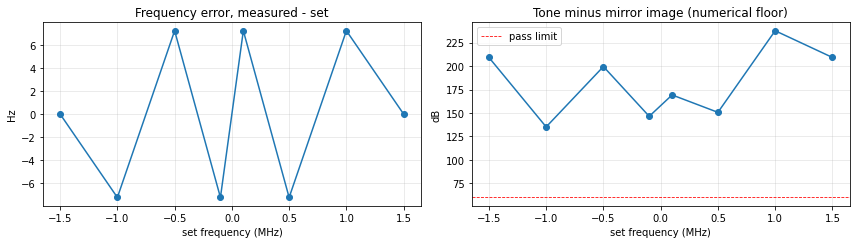

In [5]:
ad.reg_write(OBS, ad.reg_read(OBS) | 1)          # digital loopback on
time.sleep(0.05)

# ---- test 2 + 3: frequency accuracy and image (mirror) level, positive and negative frequencies
sweep = [-1.5e6, -1.0e6, -0.5e6, -0.1e6, 0.1e6, 0.5e6, 1.0e6, 1.5e6]
meas, imgs = [], []
for f in sweep:
    dds.set(freq_hz=f, amp=0.5)
    ok, x = capture_adc()
    m = spectrum_db(x)
    f_pk, l_pk = peak_of(m)
    meas.append(f_pk); imgs.append(l_pk - level_at(m, -f))
err = np.array(meas) - np.array(sweep)
check("frequency accuracy", np.abs(err).max() < 300,
      f"worst error {np.abs(err).max():.0f} Hz over {len(sweep)} frequencies from {sweep[0]/1e6:+.1f} to {sweep[-1]/1e6:+.1f} MHz (bin = {BIN:.0f} Hz)")
check("I/Q order, image rejection", min(imgs) > 60, f"mirror image at least {min(imgs):.0f} dB below the tone (digital loopback: no analog imbalance, so this is a numerical floor)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(np.array(sweep) / 1e6, err, "o-"); ax[0].set(title="Frequency error, measured - set", xlabel="set frequency (MHz)", ylabel="Hz"); ax[0].grid(alpha=.3)
ax[1].plot(np.array(sweep) / 1e6, imgs, "o-"); ax[1].axhline(60, color="r", ls="--", lw=0.8, label="pass limit"); ax[1].legend()
ax[1].set(title="Tone minus mirror image (numerical floor)", xlabel="set frequency (MHz)", ylabel="dB"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

PASS  amplitude steps of 6 dB: level steps for amp halved: 6.02 dB, 6.02 dB, 6.02 dB, 6.02 dB


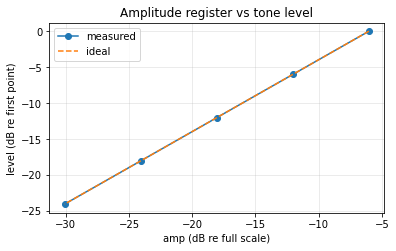

In [6]:
# ---- test 4: amplitude control
amps = [0.5, 0.25, 0.125, 0.0625, 0.03125]
lev = []
for a in amps:
    dds.set(freq_hz=500e3, amp=a)
    ok, x = capture_adc()
    lev.append(peak_of(spectrum_db(x))[1])
lev = np.array(lev)
steps = -np.diff(lev)
check("amplitude steps of 6 dB", np.abs(steps - 6.02).max() < 0.5,
      "level steps for amp halved: " + ", ".join(f"{s:.2f} dB" for s in steps))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(20 * np.log10(amps), lev - lev[0], "o-", label="measured"); ax.plot(20 * np.log10(amps), 20 * np.log10(np.array(amps) / amps[0]), "--", label="ideal")
ax.set(title="Amplitude register vs tone level", xlabel="amp (dB re full scale)", ylabel="level (dB re first point)"); ax.legend(); ax.grid(alpha=.3)
plt.show()

In [7]:
# ---- test 5: enable off, and how fast an update is taken over
dds.set(freq_hz=500e3, amp=0.5)
l_on = peak_of(spectrum_db(capture_adc()[1]))[1]
t0 = time.perf_counter(); dds.off(); t_off = time.perf_counter() - t0
time.sleep(0.02)
m_off = spectrum_db(capture_adc()[1])
l_off = level_at(m_off, 500e3)
check("enable off silences the DAC", l_on - l_off > 40, f"tone {l_on:.0f} dB -> {l_off:.0f} dB when off")
t0 = time.perf_counter()
for i in range(20):
    dds.set(freq_hz=300e3 + 10e3 * i)
t_upd = (time.perf_counter() - t0) / 20
check("update handshake", t_off < 0.05 and t_upd < 0.05, f"commit taken over after {t_off*1e3:.2f} ms (off), {t_upd*1e3:.2f} ms per frequency change")

dds.off()
ad.reg_write(OBS, ad.reg_read(OBS) & ~1)         # digital loopback off

PASS  enable off silences the DAC: tone 132 dB -> -180 dB when off
PASS  update handshake: commit taken over after 0.54 ms (off), 0.10 ms per frequency change


## Summary

In [8]:
bad = [k for k, (ok, _) in results.items() if not ok]
print("ALL TESTS PASSED" if not bad else "SOME TESTS FAILED: " + ", ".join(bad))

ALL TESTS PASSED


### If a test fails

| symptom | likely cause |
|---|---|
| `Overlay(BIT)` raises an error about connections / `pynqmetadata` | the `.hwh` was not fixed with `tools/fix_hwh.py` |
| `dds_regs` not found in `ip_dict` | the wrong `.bit`/`.hwh` pair, or the step-1 module reference is missing in the block design |
| `P501Dds(...)` says "not the DDS register block" | the address map: the register block is not at `0x9C450000` (Address Editor) |
| `TimeoutError: DDS update not taken over` | the AD9361 clock is not running: the sample-clock side takes values over only while `l_clk` runs. Run the bring-up first |
| test 1: no tone, but tests 2-5 pass | RF side: antennas/cable, TX attenuation, LO. The FPGA part is fine |
| test 2: frequency error of a few kHz or more | `FS` here differs from the real TX sample rate, so frequencies scale by the ratio |
| test 3: image just below the tone | I and Q swapped, or `cos`/`sin` taken from the wrong halves of the DDS output (`dds_scale.v`) |
| tests 2-5: tone present but spurs comb | `dac_valid` is not used as the clock enable of the DDS, so samples are repeated or skipped |
| test 4: steps of 3 or 12 dB | amplitude register format: Q15, bits 14:0 |

### Things to try

* `dds.set(freq_hz=...)` while watching a live spectrum: the update is glitch-free, the phase accumulator is never reset.
* Sweep in Python (a loop of `dds.set` with a short sleep): a chirp generated by software, with ~1 ms per step.
* In the tutorial, replace the register block by a version with a second frequency word and a hardware sweep.